In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score, ConfusionMatrixDisplay,
    confusion_matrix
)

In [2]:
df = pd.read_csv('IMDB Dataset.csv')
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [4]:
# Проверю баланс классов
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [5]:
# Проверю на дубликаты
df.duplicated(subset=['review']).sum()

np.int64(418)

In [6]:
# Группирую строки по тексту и считаем число уникальных меток
labels_per_review = df.groupby('review')['sentiment'].nunique()
(labels_per_review > 1).sum()

np.int64(0)

In [7]:
# Теперь удалим повторные отзывы
df = df.drop_duplicates(subset=['review']).reset_index(drop=True)
print(f'{df.shape}\n'
      f'{df['sentiment'].value_counts()}')

(49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [8]:
# Делим датасет, 60/20/20
x = df['review']
y = df['sentiment']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print(x_train.shape, x_val.shape, x_test.shape)

(29748,) (9917,) (9917,)


In [9]:
# Функция по чистке текста от HTML тегов и лишних пробелов
def clean_text(text):
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


x_train_clean = x_train.apply(clean_text)
x_val_clean = x_val.apply(clean_text)
x_test_clean = x_test.apply(clean_text)

In [10]:
# Обучаем tfidf векторизатор
vectorizer = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 1),
    stop_words=None,
)

x_train_tfidf = vectorizer.fit_transform(x_train_clean)
x_val_tfidf = vectorizer.transform(x_val_clean)

print(x_train_tfidf.shape, x_val_tfidf.shape)

(29748, 20000) (9917, 20000)


In [11]:
# Обучаем LogisticRegression c tfidf
model_lr_tfidf = LogisticRegression(max_iter=1000)

model_lr_tfidf.fit(x_train_tfidf, y_train)
y_val_pred = model_lr_tfidf.predict(x_val_tfidf)

# Accuracy
lr_accuracy_tfidf = accuracy_score(y_val, y_val_pred)

# F1 macro
lr_f1_tfidf = f1_score(y_val, y_val_pred, average='macro')

print(lr_accuracy_tfidf, lr_f1_tfidf)

0.8912977715034789 0.891273227330251


In [12]:
# Подбираем гиперпараметры
c_values = [0.1, 1, 10]
results = []

for C in c_values:
    model = LogisticRegression(C=C, max_iter=1000)

    model.fit(x_train_tfidf, y_train)

    y_val_pred = model.predict(x_val_tfidf)

    # Accuracy
    lr_accuracy = accuracy_score(y_val, y_val_pred)

    # F1
    lr_f1_score = f1_score(y_val, y_val_pred, average='macro')

    results.append({'C': C, 'Accuracy': lr_accuracy, 'f1_score': lr_f1_score})

results_df_tfidf = pd.DataFrame(results)
results_df_tfidf

,C,Accuracy,f1_score
0,0.1,0.859332,0.859258
1,1.0,0.891298,0.891273
2,10.0,0.895331,0.895315


In [13]:
# Лучшим себя показал С=10, обучим модель с этим гиперпараметром
best_model_tfidf = LogisticRegression(C=10, max_iter=1000)
best_model_tfidf.fit(x_train_tfidf, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [14]:
# Обучаем векторизатор BoW
vectorizer_bow = CountVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 1),
    stop_words=None,
)

x_train_bow = vectorizer_bow.fit_transform(x_train_clean)
x_val_bow = vectorizer_bow.transform(x_val_clean)

print(x_train_bow.shape, x_val_bow.shape)

(29748, 20000) (9917, 20000)


In [15]:
# Обучаем LogisticRegression c BoW
model_lr_bow = LogisticRegression(max_iter=1000)

model_lr_bow.fit(x_train_bow, y_train)
y_val_pred = model_lr_bow.predict(x_val_bow)

# Accuracy
lr_accuracy_bow = accuracy_score(y_val, y_val_pred)

# F1 macro
lr_f1_bow = f1_score(y_val, y_val_pred, average='macro')

print(lr_accuracy_bow, lr_f1_bow)

0.8796006856912373 0.8795809368299401


In [16]:
# Подбираем гиперпараметры
c_values = [0.1, 1, 10]
results = []

for C in c_values:
    model = LogisticRegression(C=C, max_iter=1000)

    model.fit(x_train_bow, y_train)

    y_val_pred = model.predict(x_val_bow)

    # Accuracy
    lr_accuracy = accuracy_score(y_val, y_val_pred)

    # F1
    lr_f1_score = f1_score(y_val, y_val_pred, average='macro')

    results.append({'C': C, 'Accuracy': lr_accuracy, 'f1_score': lr_f1_score})

results_df_bow = pd.DataFrame(results)
results_df_bow

,C,Accuracy,f1_score
0,0.1,0.892609,0.892598
1,1.0,0.879601,0.879581
2,10.0,0.871635,0.871620


In [17]:
# Самым лучшим получился С=0.1, обучим модель с этим гиперпараметром
best_model_bow = LogisticRegression(C=0.1, max_iter=1000)
best_model_bow.fit(x_train_bow, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [18]:
# Вычисляем accuracy и f1 score для каждой модели по лучшему параметру
x_test_tfidf = vectorizer.transform(x_test_clean)
x_test_bow = vectorizer_bow.transform(x_test_clean)

best_tfidf_predict = best_model_tfidf.predict(x_test_tfidf)
best_bow_predict = best_model_bow.predict(x_test_bow)

# Accuracy
best_tfidf_accuracy = accuracy_score(y_test, best_tfidf_predict)
best_bow_accuracy = accuracy_score(y_test, best_bow_predict)

# F1 score macro
best_tfidf_f1 = f1_score(y_test, best_tfidf_predict, average='macro')
best_bow_f1 = f1_score(y_test, best_bow_predict, average='macro')

In [19]:
# Сравниваем выбранные модели на тестовой выборке
comparison = pd.DataFrame({
    'Model': ['TF-IDF', 'BoW'],
    'C': [10, 0.1],
    'Accuracy': [best_tfidf_accuracy, best_bow_accuracy],
    'F1 macro': [best_tfidf_f1, best_bow_f1]
})

comparison

,Model,C,Accuracy,F1 macro
0,TF-IDF,10.0,0.895936,0.895928
1,BoW,0.1,0.893516,0.893500


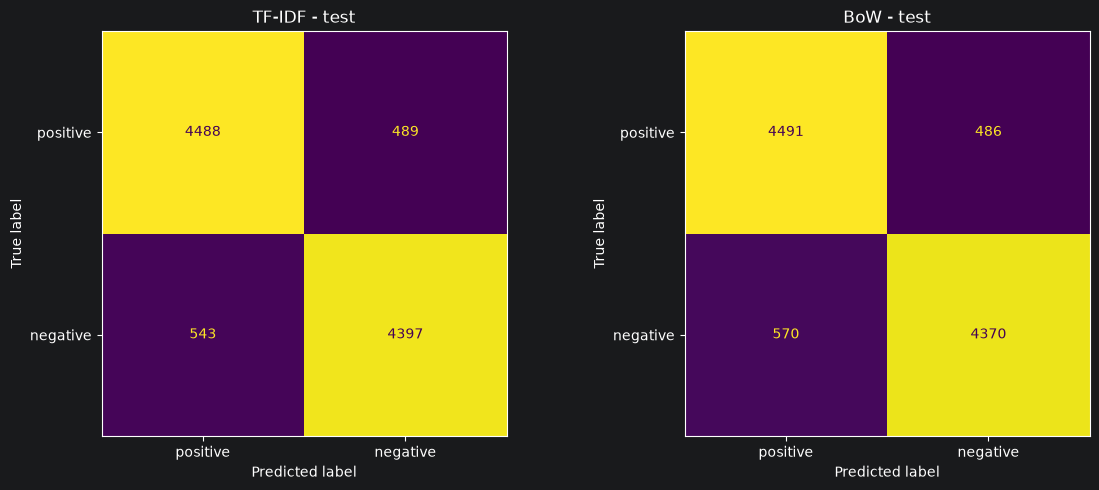

In [20]:
# Строим матрицы ошибок двух моделей на тестовой выборке
labels = ['positive', 'negative']
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

disp_tfidf = ConfusionMatrixDisplay(confusion_matrix(y_test, best_tfidf_predict, labels=labels), display_labels=labels)
disp_tfidf.plot(ax=ax[0], colorbar=False)
disp_bow = ConfusionMatrixDisplay(confusion_matrix(y_test, best_bow_predict, labels=labels), display_labels=labels)
disp_bow.plot(ax=ax[1], colorbar=False)

ax[0].set_title('TF-IDF - test')
ax[1].set_title('BoW - test')
plt.tight_layout()
plt.show()

In [21]:
# Собираем тексты, истинные метки и предсказания
test_predictions = pd.DataFrame({
    'review': x_test,
    'true_label': y_test,
    'predicted_label': best_tfidf_predict
})

# Оставляем только ошибочные предсказания
errors = test_predictions[
    test_predictions['true_label'] != test_predictions['predicted_label']
]

print(f'Количество ошибок: {len(errors)}')

# Выводим полные тексты пяти случайных ошибок
examples = errors.sample(n=min(5, len(errors)), random_state=42)

for index, row in examples.iterrows():
    print(f"\nОтзыв №{index}")
    print(f"Истинная метка: {row['true_label']}")
    print(f"Предсказание: {row['predicted_label']}")
    print(clean_text(row['review']))
    print('-' * 80)

Количество ошибок: 1032

Отзыв №36649
Истинная метка: negative
Предсказание: positive
A so common horror story about a luxury building at Brooklyn which hides the gates to hell. It is reminiscent of Polanski's "The Tenant" (released a year before "The sentinel"), but is too far from the movie of the polish filmmaker in any aspect possible. "The tenant" was so disturbing, whereas "The sentinel" is not at all. What it's more surprising from this film is the cast: it is full of great names of American cinema (Burguess, Gardner, Wallach), veteran actors acting for food (I guess). Verdict: barely entertaining. *My rate: 4/10
--------------------------------------------------------------------------------

Отзыв №31014
Истинная метка: positive
Предсказание: negative
Scientist working frantically in seclusion finds a way to locate the impact crater of a meteor carrying a new radioactive element. All (pseudo)science and breakthrough technology talks of the 1930s are right there, including the 

Для классификации отзывов IMDB сравнены TF-IDF и Bag of Words с логистической регрессией. На тестовой выборке TF-IDF показал немного лучший результат: accuracy 89,59% и F1 macro 0,8959 против 89,35% и 0,8935 у BoW. Разбор ошибок выявил возможные трудности с пониманием сочетаний слов и отличием описания сюжета от оценки фильма.